In [25]:
import pulse_simulator as ps
import functools
import qiskit_dynamics as qk_d
import qiskit.providers.fake_provider as qk_fp
import numpy as np
import csv
import qiskit
import matplotlib.pyplot as plt

In [26]:
backend = qk_fp.FakeManila()
units = 1e9
ns = units
dt = backend.configuration().dt * ns
print("dt: ", dt)

dt:  0.2222222222222222


In [27]:
N = 4

In [28]:
registers = [i for i in range(N)]
config_vars = ps.backend_simulation_vars(backend, rabi=False, units=units)

cr_model = functools.partial(
    ps.cross_resonance_model,
    registers=registers,
    backend=backend,
    variables=config_vars,
    model_name="Toy",
    qiskit_order=True,
)

# Control model
H_drift = 0.0
Hs_control = []
Hs_channels = []
for i in range(N - 1):
    control, target = i, i + 1
    Hj_drift, Hjs_control, Hjs_channel, params = cr_model(
        (control, target), return_params=True
    )
    H_drift += Hj_drift
    Hs_control += Hjs_control
    Hs_channels += Hjs_channel

In [29]:
I = np.array([[1, 0], [0, 1]])
Z = np.array([[1, 0], [0, -1]])
H_xtalk = np.kron(I, np.kron(Z, np.kron(Z, I))) + np.kron(Z, np.kron(Z, np.kron(I, I))) + np.kron(I, np.kron(I, np.kron(Z, Z)))

In [30]:
solver = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    static_dissipators=None,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    hamiltonian_channels=Hs_channels,
    channel_carrier_freqs={ch: 0.0 for ch in Hs_channels},
    dt=dt,
)
solver.model.evaluation_mode = "dense"

In [31]:
robust_sim = ps.simulator.Simulator(
    basis_gates=["rz", "sx", "x", "ecr"], solver=solver, backend=backend
)

In [32]:
# load and set one-qubit pulses
file_name = "../pico-pulses/saved-pulses-2023-12-13/a_single_qubit_gateset_R1e-5.csv"
gates = []
with open(file_name) as file:
    reader = csv.reader(file)
    for row in reader:
        gates.append(np.array([float(x) for x in row]))

for pulse, name in zip(gates, ["x_blue", "x_red", "sx_blue", "sx_red"]):
    qiskit_pulse = qiskit.pulse.Waveform(pulse, limit_amplitude=False)
    robust_sim.set_pulse(name, qiskit_pulse)

# load and set two-qubit pulses
file_name = "../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_robust.csv"
gates = []
with open(file_name) as file:
    reader = csv.reader(file)
    for row in reader:
        gates.append(np.array([float(x) for x in row]))

rzx_p = qiskit.pulse.Waveform(gates[0], limit_amplitude=False)
rzx_n = qiskit.pulse.Waveform(-gates[0], limit_amplitude=False)
robust_sim.set_pulse("zx+_blue", rzx_p)
robust_sim.set_pulse("zx+_red", rzx_p)
robust_sim.set_pulse("zx-_blue", rzx_n)
robust_sim.set_pulse("zx-_red", rzx_n)

In [33]:
default_sim = ps.simulator.Simulator(
    basis_gates=["rz", "sx", "x", "ecr"], solver=solver, backend=backend
)

In [34]:
# load and set one-qubit pulses
file_name = "../pico-pulses/saved-pulses-2023-12-13/a_single_qubit_gateset_default.csv"
gates = []
with open(file_name) as file:
    reader = csv.reader(file)
    for row in reader:
        gates.append(np.array([float(x) for x in row]))

for pulse, name in zip(gates, ["x_blue", "x_red", "sx_blue", "sx_red"]):
    qiskit_pulse = qiskit.pulse.Waveform(pulse, limit_amplitude=False)
    default_sim.set_pulse(name, qiskit_pulse)

# load and set two-qubit pulses
file_name = "../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_default.csv"
gates = []
with open(file_name) as file:
    reader = csv.reader(file)
    for row in reader:
        gates.append(np.array([float(x) for x in row]))

rzx_p = qiskit.pulse.Waveform(gates[0], limit_amplitude=False)
rzx_n = qiskit.pulse.Waveform(-gates[0], limit_amplitude=False)
default_sim.set_pulse("zx+_blue", rzx_p)
default_sim.set_pulse("zx+_red", rzx_p)
default_sim.set_pulse("zx-_blue", rzx_n)
default_sim.set_pulse("zx-_red", rzx_n)

### Control-target

In [35]:
H_drift = 0.0
Hs_control = []
Hs_channels = []
for control, target in [(0, 1), (2, 3)]:
    Hj_drift, Hjs_control, Hjs_channel, params = cr_model(
        (control, target), return_params=True
    )
    H_drift += Hj_drift
    Hs_control += Hjs_control
    Hs_channels += Hjs_channel

In [36]:
qc = qiskit.QuantumCircuit(N)
qc.ecr(0, 1)
qc.ecr(2, 3)
qc.draw()

┌──────┐
q_0: ┤0     ├
     │  Ecr │
q_1: ┤1     ├
     ├──────┤
q_2: ┤0     ├
     │  Ecr │
q_3: ┤1     ├
     └──────┘

In [37]:
default_fidelities = []
robust_fidelities = []
strength_array = np.arange(0, 0.1, 0.005)
expected = qiskit.quantum_info.Operator(qc)

for strength in strength_array:
    solver = qk_d.Solver(
        static_hamiltonian=H_xtalk * strength,
        hamiltonian_operators=Hs_control,
        static_dissipators=None,
        rotating_frame=None,
        rwa_cutoff_freq=None,
        hamiltonian_channels=Hs_channels,
        channel_carrier_freqs={ch: 0.0 for ch in Hs_channels},
        dt=dt,
    )
    solver.model.evaluation_mode = "dense"
    default_sim.set_solver(solver)
    robust_sim.set_solver(solver)

    default_out = default_sim.simulate_circuit(qc)
    robust_out = robust_sim.simulate_circuit(qc)

    default_fidelities.append(qiskit.quantum_info.process_fidelity(default_out, expected))
    robust_fidelities.append(qiskit.quantum_info.process_fidelity(robust_out, expected))

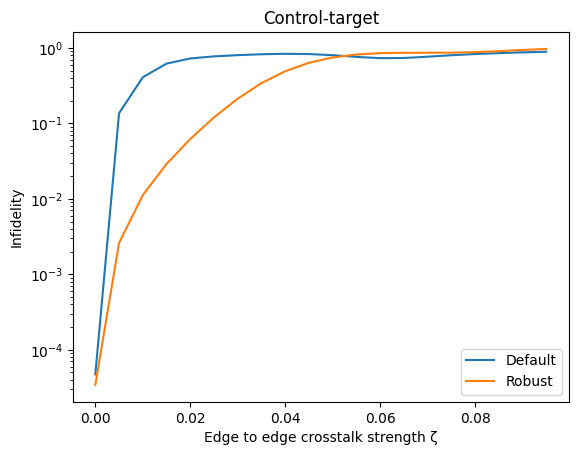

In [38]:
plt.plot(strength_array, 1 - np.array(default_fidelities), label="Default")
plt.plot(strength_array, 1 - np.array(robust_fidelities), label="Robust")
plt.yscale("log")
plt.xlabel("Edge to edge crosstalk strength ζ")
plt.ylabel("Infidelity")
plt.title("Control-target")
plt.legend();

### Control-control

In [39]:
H_drift = 0.0
Hs_control = []
Hs_channels = []
for control, target in [(1, 0), (2, 3)]:
    Hj_drift, Hjs_control, Hjs_channel, params = cr_model(
        (control, target), return_params=True
    )
    H_drift += Hj_drift
    Hs_control += Hjs_control
    Hs_channels += Hjs_channel

In [40]:
qc = qiskit.QuantumCircuit(N)
qc.ecr(1, 0)
qc.ecr(2, 3)
qc.draw()

┌──────┐
q_0: ┤1     ├
     │  Ecr │
q_1: ┤0     ├
     ├──────┤
q_2: ┤0     ├
     │  Ecr │
q_3: ┤1     ├
     └──────┘

In [41]:
default_fidelities = []
robust_fidelities = []
strength_array = np.arange(0, 0.1, 0.005)
expected = qiskit.quantum_info.Operator(qc)

for strength in strength_array:
    solver = qk_d.Solver(
        static_hamiltonian=H_xtalk * strength,
        hamiltonian_operators=Hs_control,
        static_dissipators=None,
        rotating_frame=None,
        rwa_cutoff_freq=None,
        hamiltonian_channels=Hs_channels,
        channel_carrier_freqs={ch: 0.0 for ch in Hs_channels},
        dt=dt,
    )
    solver.model.evaluation_mode = "dense"
    default_sim.set_solver(solver)
    robust_sim.set_solver(solver)

    default_out = default_sim.simulate_circuit(qc)
    robust_out = robust_sim.simulate_circuit(qc)

    default_fidelities.append(qiskit.quantum_info.process_fidelity(default_out, expected))
    robust_fidelities.append(qiskit.quantum_info.process_fidelity(robust_out, expected))

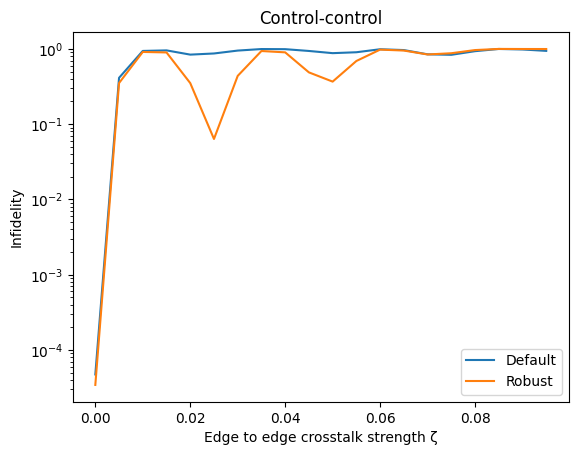

In [42]:
plt.plot(strength_array, 1 - np.array(default_fidelities), label="Default")
plt.plot(strength_array, 1 - np.array(robust_fidelities), label="Robust")
plt.yscale("log")
plt.xlabel("Edge to edge crosstalk strength ζ")
plt.ylabel("Infidelity")
plt.title("Control-control")
plt.legend();

### Target-target

In [43]:
H_drift = 0.0
Hs_control = []
Hs_channels = []
for control, target in [(0, 1), (3, 2)]:
    Hj_drift, Hjs_control, Hjs_channel, params = cr_model(
        (control, target), return_params=True
    )
    H_drift += Hj_drift
    Hs_control += Hjs_control
    Hs_channels += Hjs_channel

In [44]:
qc = qiskit.QuantumCircuit(N)
qc.ecr(0, 1)
qc.ecr(3, 2)
qc.draw()

┌──────┐
q_0: ┤0     ├
     │  Ecr │
q_1: ┤1     ├
     ├──────┤
q_2: ┤1     ├
     │  Ecr │
q_3: ┤0     ├
     └──────┘

In [45]:
default_fidelities = []
robust_fidelities = []
strength_array = np.arange(0, 0.1, 0.005)
expected = qiskit.quantum_info.Operator(qc)

for strength in strength_array:
    solver = qk_d.Solver(
        static_hamiltonian=H_xtalk * strength,
        hamiltonian_operators=Hs_control,
        static_dissipators=None,
        rotating_frame=None,
        rwa_cutoff_freq=None,
        hamiltonian_channels=Hs_channels,
        channel_carrier_freqs={ch: 0.0 for ch in Hs_channels},
        dt=dt,
    )
    solver.model.evaluation_mode = "dense"
    default_sim.set_solver(solver)
    robust_sim.set_solver(solver)

    default_out = default_sim.simulate_circuit(qc)
    robust_out = robust_sim.simulate_circuit(qc)

    default_fidelities.append(qiskit.quantum_info.process_fidelity(default_out, expected))
    robust_fidelities.append(qiskit.quantum_info.process_fidelity(robust_out, expected))

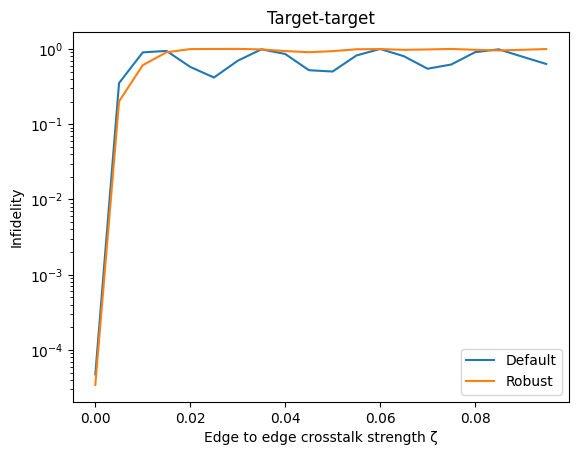

In [46]:
plt.plot(strength_array, 1 - np.array(default_fidelities), label="Default")
plt.plot(strength_array, 1 - np.array(robust_fidelities), label="Robust")
plt.yscale("log")
plt.xlabel("Edge to edge crosstalk strength ζ")
plt.ylabel("Infidelity")
plt.title("Target-target")
plt.legend();